# 1. Disparo lineal

Problema de contorno lineal de segundo orden en $[a, b]$:

$$
y'' = p(x)\, y' + q(x)\, y + r(x),
$$

con condiciones de contorno de tipo Robin en los dos extremos:

$$
\alpha_1\, y(a) + \beta_1\, y'(a) = \gamma_1, \qquad
\alpha_2\, y(b) + \beta_2\, y'(b) = \gamma_2 .
$$

Las condiciones de Dirichlet ($\beta = 0$) y de Neumann ($\alpha = 0$) son
casos particulares, así que todo lo que sigue vale también para ellas.

## Idea del método de disparo

Convertimos el problema de contorno en un **problema de valor inicial** que
depende de un parámetro $t$, y buscamos el $t$ con el que la solución cumple
la condición en $x = b$.

**Datos iniciales.** La condición en $x = a$ fija $y(a)$ e $y'(a)$ salvo un
grado de libertad:

- si $\beta_1 \neq 0$, tomamos $y(a) = t$ y despejamos
  $y'(a) = \dfrac{\gamma_1 - \alpha_1 t}{\beta_1}$;
- si $\beta_1 = 0$ (Dirichlet), $y(a) = \gamma_1 / \alpha_1$ queda fijado y
  disparamos con la pendiente, $y'(a) = t$.

**Ecuación del disparo.** Si llamamos $y(x; t)$ a la solución del problema
de valor inicial, queremos resolver

$$
F(t) = \alpha_2\, y(b; t) + \beta_2\, y'(b; t) - \gamma_2 = 0 .
$$

## Superposición

Como la ecuación es lineal y los datos iniciales dependen de $t$ de forma
afín, la solución también es afín en $t$:

$$
y(x; t) = u(x) + t\, v(x),
$$

donde

- $u$ resuelve la ecuación **completa** con los datos iniciales de $t = 0$;
- $v$ resuelve la ecuación **homogénea**
  $v'' = p(x)\, v' + q(x)\, v$ con datos iniciales
  $\left(v(a), v'(a)\right) = \left(\partial_t y(a), \partial_t y'(a)\right)$,
  es decir $(1, -\alpha_1/\beta_1)$ si $\beta_1 \neq 0$ o $(0, 1)$ si
  $\beta_1 = 0$.

Entonces $F(t) = F(0) + t \left(\alpha_2\, v(b) + \beta_2\, v'(b)\right)$ y
basta **un único despeje**, sin iterar:

$$
t^\ast = -\frac{F(0)}{\alpha_2\, v(b) + \beta_2\, v'(b)} .
$$

Si el denominador es cero, el problema no tiene solución única.

Resolvemos los dos problemas de valor inicial con Runge-Kutta de orden 4 y
$N$ subintervalos (`bvp.rk4`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from bvp import Robin, dirichlet, linear_shooting

In [2]:
from IPython.display import Markdown, display


def table(headers, rows, fmt="{:.6g}"):
    """Show rows as a Markdown table."""
    def cell(v):
        return fmt.format(v) if isinstance(v, float) else str(v)

    lines = ["| " + " | ".join(headers) + " |",
             "|" + "---:|" * len(headers)]
    lines += ["| " + " | ".join(cell(v) for v in row) + " |"
              for row in rows]
    display(Markdown("\n".join(lines)))

## Ejemplo 1: condiciones de Dirichlet

Ejemplo clásico de Burden y Faires:

$$
y'' = -\frac{2}{x}\, y' + \frac{2}{x^2}\, y + \frac{\sin(\ln x)}{x^2},
\qquad x \in [1, 2], \qquad y(1) = 1, \quad y(2) = 2,
$$

con solución exacta

$$
y(x) = c_1 x + \frac{c_2}{x^2} - \frac{3}{10}\sin(\ln x)
- \frac{1}{10}\cos(\ln x),
\quad c_2 = \frac{8 - 12\sin(\ln 2) - 4\cos(\ln 2)}{70},
\quad c_1 = \frac{11}{10} - c_2 .
$$

In [3]:
def p1(x):
    return -2 / x


def q1(x):
    return 2 / x**2


def r1(x):
    return np.sin(np.log(x)) / x**2


def exact1(x):
    c2 = (8 - 12 * np.sin(np.log(2)) - 4 * np.cos(np.log(2))) / 70
    c1 = 11 / 10 - c2
    return (c1 * x + c2 / x**2 - 3 / 10 * np.sin(np.log(x))
            - 1 / 10 * np.cos(np.log(x)))


res1 = linear_shooting(p1, q1, r1, 1, 2, dirichlet(1), dirichlet(2), n=10)
print(f"t* = y'(1) = {res1.t:.10f}")
table(["$x_i$", "$w_i$", "$y(x_i)$", "$|w_i - y(x_i)|$"],
      [(x, w, exact1(x), f"{abs(w - exact1(x)):.2e}")
       for x, w in zip(res1.x, res1.y)])

t* = y'(1) = 0.9176213964


| $x_i$ | $w_i$ | $y(x_i)$ | $|w_i - y(x_i)|$ |
|---:|---:|---:|---:|
| 1 | 1 | 1 | 0.00e+00 |
| 1.1 | 1.09263 | 1.09263 | 1.34e-07 |
| 1.2 | 1.18708 | 1.18708 | 1.34e-07 |
| 1.3 | 1.28338 | 1.28338 | 9.78e-08 |
| 1.4 | 1.38145 | 1.38145 | 6.02e-08 |
| 1.5 | 1.48116 | 1.48116 | 3.06e-08 |
| 1.6 | 1.58239 | 1.58239 | 1.08e-08 |
| 1.7 | 1.68501 | 1.68501 | 5.44e-10 |
| 1.8 | 1.7889 | 1.7889 | 5.05e-09 |
| 1.9 | 1.89393 | 1.89393 | 4.41e-09 |
| 2 | 2 | 2 | 0.00e+00 |

## Ejemplo 2: condiciones de Robin

$$
y'' = -y, \qquad x \in [0, \pi/2], \qquad
y(0) + y'(0) = 2, \quad 2\, y(\pi/2) + y'(\pi/2) = 1,
$$

con solución exacta $y = \sin x + \cos x$. Aquí $\beta_1 = 1 \neq 0$, así
que el parámetro es $t = y(0)$ (el valor exacto es $t^\ast = 1$).

t* = y(0) = 1.0000075525
error máximo en los nodos: 7.55e-06


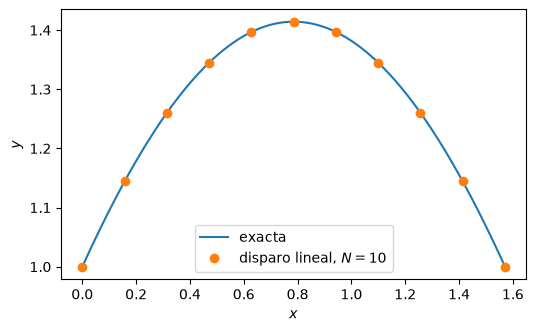

In [4]:
res2 = linear_shooting(lambda x: 0, lambda x: -1, lambda x: 0,
                       0, np.pi / 2, Robin(1, 1, 2), Robin(2, 1, 1), n=10)
exact2 = np.sin(res2.x) + np.cos(res2.x)
print(f"t* = y(0) = {res2.t:.10f}")
print(f"error máximo en los nodos: {np.max(np.abs(res2.y - exact2)):.2e}")

xs = np.linspace(0, np.pi / 2, 200)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(xs, np.sin(xs) + np.cos(xs), label="exacta")
ax.plot(res2.x, res2.y, "o", label="disparo lineal, $N = 10$")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.legend()
plt.show()

## Orden de convergencia

El disparo lineal hereda el orden del integrador: con RK4, al duplicar $N$
el error debería dividirse por $2^4 = 16$.

In [5]:
ns = [5, 10, 20, 40, 80]
errors = []
for n in ns:
    r = linear_shooting(p1, q1, r1, 1, 2, dirichlet(1), dirichlet(2), n=n)
    errors.append(np.max(np.abs(r.y - exact1(r.x))))

table(["$N$", "error máximo", "cociente"],
      [(n, f"{e:.3e}", "" if i == 0 else f"{errors[i - 1] / e:.1f}")
       for i, (n, e) in enumerate(zip(ns, errors))])

| $N$ | error máximo | cociente |
|---:|---:|---:|
| 5 | 2.735e-06 |  |
| 10 | 1.343e-07 | 20.4 |
| 20 | 7.736e-09 | 17.4 |
| 40 | 4.483e-10 | 17.3 |
| 80 | 2.702e-11 | 16.6 |